# Steering the helix face angle
Instead of ablating the angle (notebook 3), steer the residue's representation from its own angle to other angles with the harmonic fit $f(\theta) = a + b\cos\theta + c\sin\theta$ of the train-set bin means:
$h \leftarrow h - f(\theta_{own}) + f(\theta_{target})$, at the masked residue, at layer 30.
- Source residues: 4 bins of 5 degrees of the test set (0, 90, 180 and -90 degrees), 5000 residues per bin, one residue per protein
- Targets: 72 angles, every 5 degrees. Controls: random vectors with the norm of the steering edit to source + 45, 90, 180 and -90 degrees
- Endpoints: change of the probability mass on hydrophobic amino acids (Eisenberg consensus scale > 0), and of the expected Eisenberg hydrophobicity of the prediction; the logits are saved for other metrics

In [1]:
import json

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from tqdm.auto import tqdm
from transformers import AutoTokenizer, EsmForMaskedLM

from biomanifolds import config, theme
from biomanifolds.datasets import swissprot
from biomanifolds.labels import af2_structure_labels

theme.use()  # Nunito fonts and the project defaults

LAYERS = [30]
MODEL = "facebook/esm2_t30_150M_UR50D"
AA = "ACDEFGHIKLMNPQRSTVWY"  # order of the saved amino-acid log-probabilities
SOURCE_ANGLES = [0, 90, 180, -90]  # centres of the source bins, degrees
BIN_WIDTH = 5  # degrees
N_PER_BIN = 5000  # residues per source bin, one per protein
TARGETS = np.arange(-180, 180, 5)  # target angles, degrees
CONTROL_OFFSETS = [45, 90, 180, -90]  # random-vector controls, with the norm of the steering edit to source + offset
OUT_DIR = config.data_path("steering") / "nb05"  # results of this notebook
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Bin sums and counts of helix face on the train set, for each layer (from notebook 2): bin k is [k - 180, k - 179) degrees
B_harmonic = {}
theta = np.deg2rad(np.arange(360) - 179.5)  # centre of each 1-degree bin, in radians
for layer in LAYERS:
    sums = np.load(config.data_path("label_bins") / f"train_helix_face_1deg_bin_sums_L{layer}.npy")
    counts = np.load(config.data_path("label_bins") / f"train_helix_face_1deg_bin_counts_L{layer}.npy")
    weights = np.sqrt(counts)[:, None]  # least squares on the bin means, weighted by the residues per bin
    X = np.column_stack([np.ones(360), np.cos(theta), np.sin(theta)])
    B_harmonic[layer] = np.linalg.lstsq(X * weights, sums / counts[:, None] * weights, rcond=None)[0]  # (3, 640): a, b, c


def harmonic_activation(t, layer):
    """f(t) for angles t (radians, any shape): (..., 640)."""
    t = np.asarray(t)
    return np.stack([np.ones_like(t), np.cos(t), np.sin(t)], -1) @ B_harmonic[layer]


# ESM-2 with its amino-acid head, to read the logits at the masked residue
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = EsmForMaskedLM.from_pretrained(MODEL, attn_implementation="sdpa").eval().to(device)

# All test proteins
sequences = pl.read_parquet(swissprot.swissprot_dir() / "swissprot.parquet", columns=["accession", "sequence"])
splits = pl.read_parquet(swissprot.swissprot_dir() / "splits" / "splits.parquet", columns=["accession", "split"])
test_proteins = sequences.join(splits.filter(pl.col("split") == "test"), on="accession").select("accession", "sequence").sort("accession")
test_proteins

(null): No such file or directory


(null): No such file or directory


Loading weights:   0%|          | 0/491 [00:00<?, ?it/s]

accession,sequence
str,str
"""A0A017TC06""","""MIDASSLKALVRRAEGGLVEALGLRPLQLD…"
"""A0A023PXA5""","""MLLSELVATASSLPYTAISIHNNCRVPAAR…"
"""A0A023PXB0""","""MFINGFVNYPVRTPPNDLLQVVLHGFLRCP…"
"""A0A023PXB5""","""MFALIISSKGKTSGFFFNSSFSSSALVGIA…"
"""A0A023PXC2""","""MLPLCLTFLSFFLSLGGSFKAVMTKEEADG…"
…,…
"""X0JZ91""","""MIASIRTTRRLSNYNSVIPPPEPLNTDPDM…"
"""X1WER2""","""MATVEELKLRIRELENELIKSKQKQSDAEH…"
"""X4Y2L4""","""MKEIAVTIDDKNVIASVSESFHGVAFDASL…"


## Sampling the source residues
All helix residues of the test set (residues with a helix face). For each source bin: the residues whose own angle is within 2.5 degrees of the source angle, then one random residue per protein, then 5000 random proteins.

source_angle,helix_residues_in_bin,proteins_in_bin,chosen_residues,chosen_proteins
i64,i64,i64,i64,i64
0,118131,51917,5000,5000
90,120799,51943,5000,5000
180,123080,52379,5000,5000
-90,121317,51228,5000,5000


8,836,913 helix residues in 73,853 test proteins; 20,000 source residues in 17,227 distinct proteins


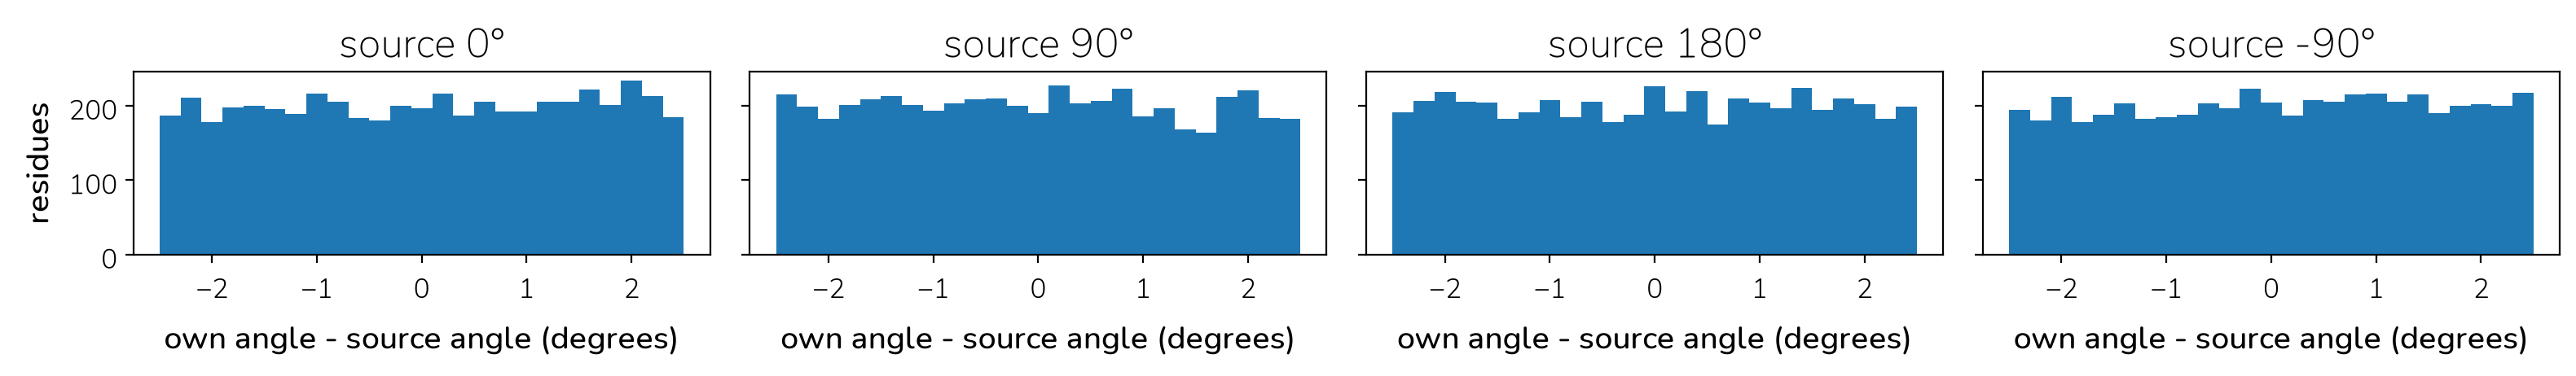

accession,i,helix_face,source_angle,sequence
str,i32,f32,i32,str
"""O95562""",82,0.619138,0,"""MDKLKKVLSGQDTEDRSGLSEVVEASSLSW…"
"""D3ZX08""",498,-0.00619,0,"""MAASVAAAAGRLRRAIGRSCPWQRFSTEPH…"
"""P64133""",51,-2.103149,0,"""MRVVFMGTPEFSVPILTAIIGHGYEVVAAY…"
"""B0RHB5""",81,2.032092,0,"""MSTLARTAHVTRQTSESSIDLRLDLDGTGA…"
"""Q3KQ10""",140,1.203546,0,"""MATVRPFDKMPMLNAAALLLVGTEESHREQ…"
…,…,…,…,…
"""Q87BW1""",75,-92.492981,-90,"""MPFVVAIPARFSASRLPGKPLRLLGGRPLI…"
"""Q9BXU7""",305,-92.394356,-90,"""MAALFLRGFVQIGNCKTGISKSKEAFIEAV…"
"""P95980""",346,-87.759384,-90,"""MSFQMKYDIRLRFEVEGIVEKTDVIGAIFG…"


In [2]:
helix_residues = (
    af2_structure_labels.load_labels(["accession", "i", "helix_face"])
    .filter(pl.col("helix_face").is_not_null())
    .join(test_proteins.select("accession").lazy(), on="accession")
    .collect(engine="streaming")
    .sort("accession", "i")  # fixed order, so that the sample is reproducible
)

samples, counts = [], []
for source in SOURCE_ANGLES:
    # angular distance below half a bin, with the wrap-around at +-180 degrees
    candidates = helix_residues.filter((pl.col("helix_face") - source).radians().cos() > np.cos(np.deg2rad(BIN_WIDTH / 2)))
    chosen = (
        candidates.sample(fraction=1.0, shuffle=True, seed=0)  # random order
        .unique("accession", keep="first", maintain_order=True)  # one random residue per protein
        .head(N_PER_BIN)  # random proteins
        .with_columns(source_angle=pl.lit(source))
    )
    samples.append(chosen)
    counts.append({"source_angle": source, "helix_residues_in_bin": len(candidates), "proteins_in_bin": candidates["accession"].n_unique(),
                   "chosen_residues": len(chosen), "chosen_proteins": chosen["accession"].n_unique()})
residues = pl.concat(samples).join(test_proteins, on="accession", maintain_order="left")  # with the protein sequences
display(pl.DataFrame(counts))
print(f"{len(helix_residues):,} helix residues in {helix_residues['accession'].n_unique():,} test proteins; "
      f"{len(residues):,} source residues in {residues['accession'].n_unique():,} distinct proteins")

# own angles of the chosen residues, around each source angle
fig, axes = plt.subplots(1, len(SOURCE_ANGLES), figsize=(16, 2.5), sharey=True)
for ax, source in zip(axes, SOURCE_ANGLES):
    own = residues.filter(pl.col("source_angle") == source)["helix_face"].to_numpy()
    ax.hist((own - source + 180) % 360 - 180, bins=np.linspace(-BIN_WIDTH / 2, BIN_WIDTH / 2, 26))
    ax.set_title(f"source {source}°")
    ax.set_xlabel("own angle - source angle (degrees)")
axes[0].set_ylabel("residues")
plt.tight_layout()
plt.show()
residues

## Steering
For each source residue: one masked forward pass to layer 30, then one copy of the residual stream at the masked position per edit, each through the final layer norm and the amino-acid head (the edits at layer 30 do not run any more layers).

In [3]:
EDITS = (["none"] + [f"target {t}" for t in TARGETS] + [f"random vector {o}" for o in CONTROL_OFFSETS])
EDIT_INFO = pl.DataFrame({
    "edit": EDITS,
    "kind": ["none"] + ["steer"] * len(TARGETS) + ["random vector"] * len(CONTROL_OFFSETS),
    "target_angle": [None] + TARGETS.tolist() + [None] * len(CONTROL_OFFSETS),
    "control_offset": [None] * (1 + len(TARGETS)) + CONTROL_OFFSETS,
}, schema_overrides={"target_angle": pl.Float64, "control_offset": pl.Int64})
AA_IDS = tokenizer.convert_tokens_to_ids(list(AA))  # vocabulary ids of the 20 amino acids
N_LAYERS = len(model.esm.encoder.layer)


def run_layers(h, start, end):
    """Run ESM layers start+1 .. end on the hidden states h (batch, tokens, 640)."""
    rotary = model.esm.rotary_embeddings(h, torch.arange(h.shape[1], device=h.device)[None])  # rotary position embeddings
    for block in model.esm.encoder.layer[start:end]:
        h = block(h, position_embeddings=rotary)
    return h


def edit_vectors(n, own):
    """The changes added to h at the masked position, {layer: (edits, 640)}: f(target) - f(own), and the random-vector controls.

    One random generator per residue (n: its row in `residues`); draws: for each layer and control offset, one random direction (640,)."""
    residue_rng = np.random.default_rng([0, n])
    own = np.deg2rad(own)
    deltas = {}
    for layer in LAYERS:
        steer = harmonic_activation(np.deg2rad(TARGETS), layer) - harmonic_activation(own, layer)  # (targets, 640)
        controls = []
        for offset in CONTROL_OFFSETS:
            direction = residue_rng.standard_normal(640)
            norm = np.linalg.norm(harmonic_activation(own + np.deg2rad(offset), layer) - harmonic_activation(own, layer))
            controls.append(direction / np.linalg.norm(direction) * norm)
        deltas[layer] = np.concatenate([np.zeros((1, 640)), steer, np.stack(controls)])
    return deltas


(OUT_DIR / "results").mkdir(exist_ok=True)
for source in SOURCE_ANGLES:  # one results file per source bin; finished files are skipped, so the cell can run again after a crash
    path = OUT_DIR / "results" / f"source_{source}.parquet"
    if path.exists():
        continue
    blocks = []
    source_residues = residues.with_row_index("n").filter(pl.col("source_angle") == source)
    for n, i, own, sequence in tqdm(source_residues.select("n", "i", "helix_face", "sequence").iter_rows(), total=len(source_residues), desc=f"source {source}"):
        tokens = tokenizer([sequence], return_tensors="pt").to(device)
        position = i + 1  # token 0 is <cls>
        tokens["input_ids"][0, position] = tokenizer.mask_token_id
        deltas = edit_vectors(n, own)
        with torch.no_grad():
            h = model.esm.embeddings(input_ids=tokens["input_ids"], attention_mask=tokens["attention_mask"])
            previous = 0
            for layer in LAYERS:
                h = run_layers(h, previous, layer)  # unedited, up to `layer`
                previous = layer
                edited = h.repeat(len(EDITS), 1, 1)  # one copy per edit
                edited[:, position] += torch.tensor(deltas[layer], dtype=torch.float32, device=device)
                edited = run_layers(edited, layer, N_LAYERS)
                logits = model.lm_head(model.esm.encoder.emb_layer_norm_after(edited[:, position]))  # (edits, vocabulary)
                blocks.append(pl.DataFrame({
                    "n": n, "layer": layer, "edit": EDITS, "edit_norm": np.linalg.norm(deltas[layer], axis=1),
                    "logits": logits.float().cpu().numpy(),  # all vocabulary logits, in the order of the tokenizer vocabulary
                    "aa_log_probs": logits.log_softmax(-1)[:, AA_IDS].float().cpu().numpy(),  # log-probabilities of the 20 amino acids, in the order of AA
                }))
    rows = (
        pl.concat(blocks)
        .join(residues.with_row_index("n"), on="n", maintain_order="left")
        .join(EDIT_INFO, on="edit", maintain_order="left")
        .with_columns(aa=pl.col("sequence").str.slice(pl.col("i"), 1))
        .select("accession", "i", "aa", "helix_face", "source_angle", "layer", "edit", "kind", "target_angle", "control_offset",
                "edit_norm", "logits", "aa_log_probs")
    )
    rows.write_parquet(path.with_suffix(".tmp"))
    path.with_suffix(".tmp").rename(path)  # a results file exists only when it is complete

results = pl.read_parquet(OUT_DIR / "results" / "*.parquet")
(OUT_DIR / "metadata.json").write_text(json.dumps({
    "model": MODEL, "layers": LAYERS, "source_angles": SOURCE_ANGLES, "bin_width": BIN_WIDTH, "n_per_bin": N_PER_BIN,
    "targets": TARGETS.tolist(), "control_offsets": CONTROL_OFFSETS, "sample_seed": 0,
    "edit": "h <- h - f(own) + f(target) at the masked residue, f: harmonic fit on the train-set bin means",
    "residue_rng": "np.random.default_rng([0, n]), n = row of the residue in `residues`; draws: per layer and control offset a random direction",
    "logits_order": tokenizer.convert_ids_to_tokens(list(range(len(tokenizer)))), "aa_log_probs_order": AA,
}, indent=1))
results

accession,i,aa,helix_face,source_angle,layer,edit,kind,target_angle,control_offset,edit_norm,logits,aa_log_probs
str,i32,str,f32,i32,i32,str,str,f64,i64,f64,"array[f32, 33]","array[f32, 20]"
"""O60156""",234,"""G""",-92.066711,-90,30,"""none""","""none""",null,null,0.0,"[-15.493483, -24.437325, … -24.448242]","[-1.347833, -4.537105, … -6.645197]"
"""O60156""",234,"""G""",-92.066711,-90,30,"""target -180""","""steer""",-180.0,null,38.229288,"[-15.575011, -24.201096, … -24.220764]","[-1.722916, -5.29599, … -6.55996]"
"""O60156""",234,"""G""",-92.066711,-90,30,"""target -175""","""steer""",-175.0,null,37.281242,"[-15.575327, -24.212452, … -24.231428]","[-1.717288, -5.291649, … -6.556942]"
"""O60156""",234,"""G""",-92.066711,-90,30,"""target -170""","""steer""",-170.0,null,36.136642,"[-15.575672, -24.22571, … -24.244009]","[-1.709054, -5.281288, … -6.55406]"
"""O60156""",234,"""G""",-92.066711,-90,30,"""target -165""","""steer""",-165.0,null,34.799365,"[-15.575964, -24.240694, … -24.258318]","[-1.698284, -5.26502, … -6.551452]"
…,…,…,…,…,…,…,…,…,…,…,…,…
"""A9A6Q2""",366,"""I""",88.95459,90,30,"""target 175""","""steer""",175.0,null,30.977303,"[-13.440548, -20.166609, … -20.142828]","[-2.770354, -5.290458, … -1.95442]"
"""A9A6Q2""",366,"""I""",88.95459,90,30,"""random vector 45""","""random vector""",null,45,21.782624,"[-13.362387, -19.967604, … -19.943705]","[-2.795122, -4.800411, … -1.459101]"
"""A9A6Q2""",366,"""I""",88.95459,90,30,"""random vector 90""","""random vector""",null,90,31.22234,"[-13.653789, -20.24613, … -20.230139]","[-2.744066, -4.735276, … -1.536078]"


## Results
Probability mass on hydrophobic amino acids (Eisenberg consensus scale > 0), normalised over the 20 amino acids, and the expected Eisenberg hydrophobicity of the prediction, $\sum_{aa} p(aa) H(aa)$: change against the unedited pass of the same residue, averaged over the residues of each source bin. One residue per protein, so the residues are independent: 95% confidence intervals from the standard error.

source_angle,layer,mass_unedited,h_unedited
i32,i32,f32,f64
-90,30,0.559166,0.056957
0,30,0.680185,0.300699
90,30,0.545554,-0.023657
180,30,0.443762,-0.182634


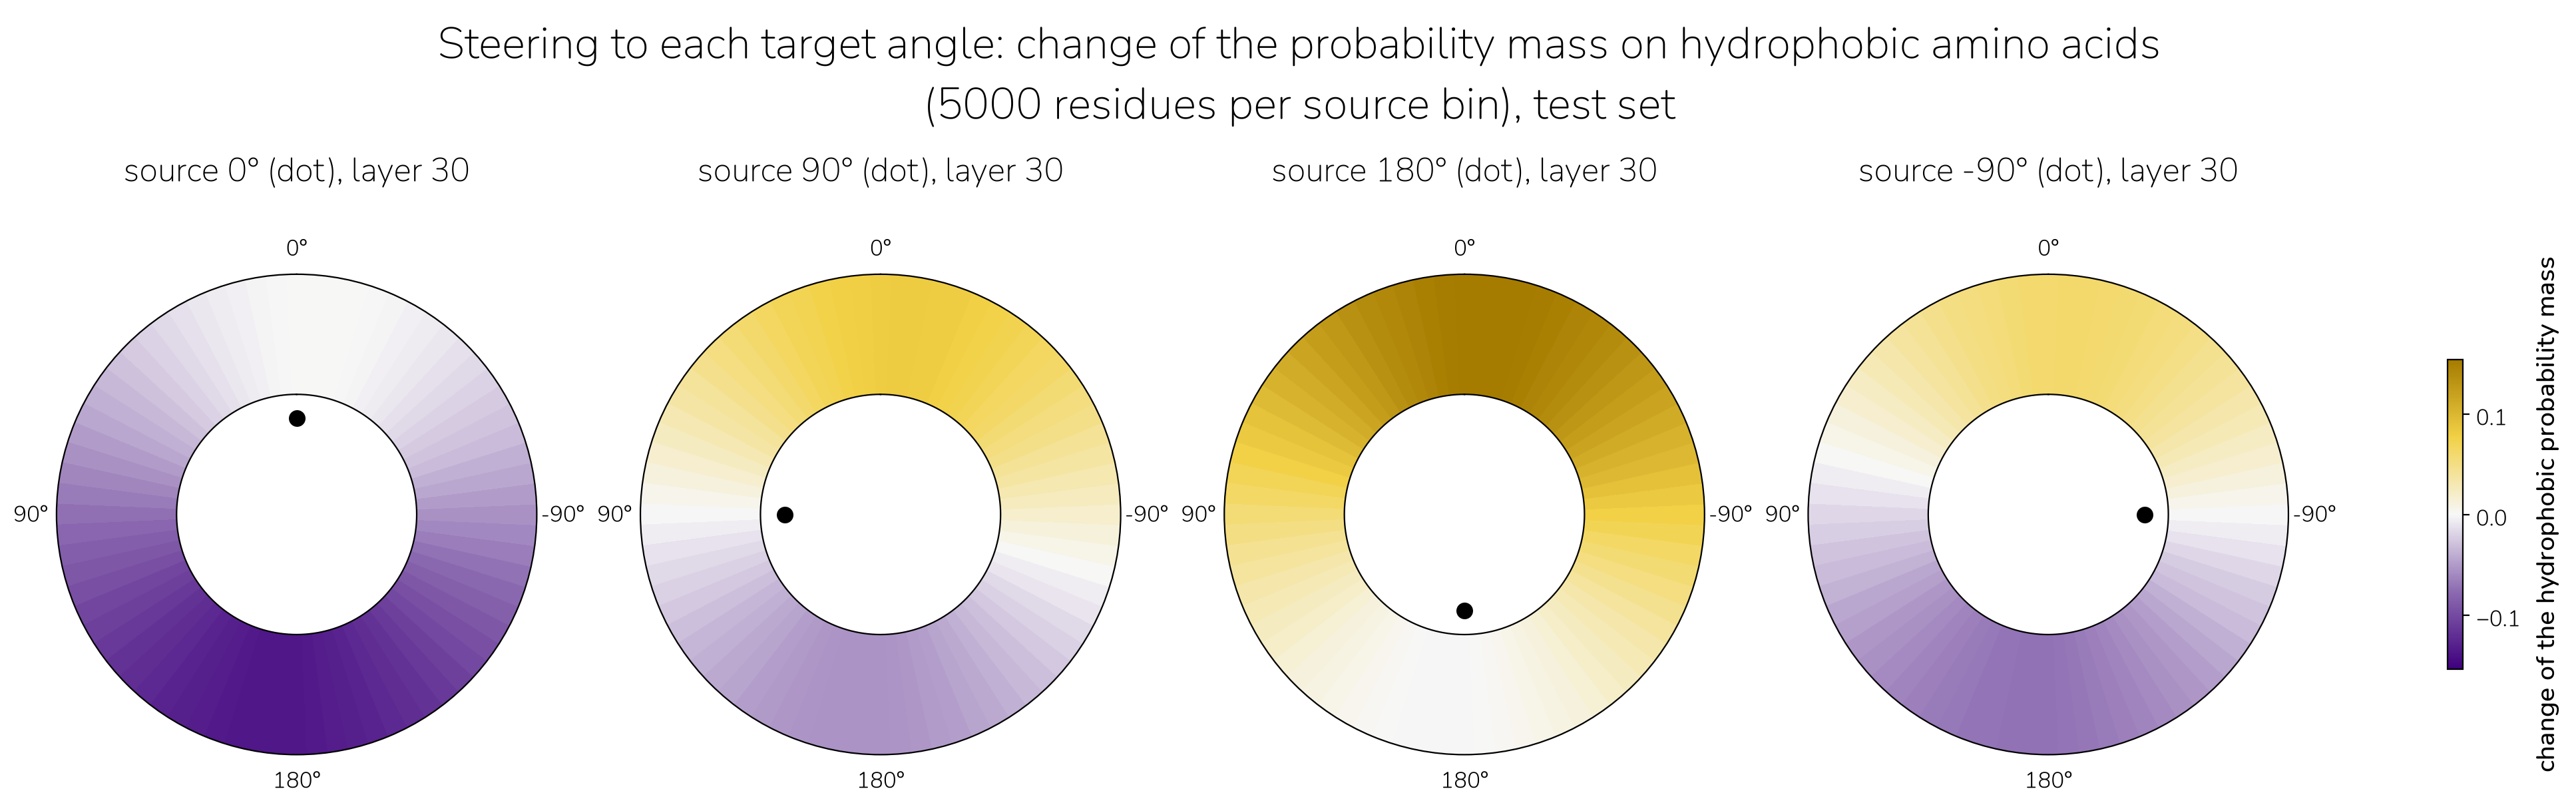

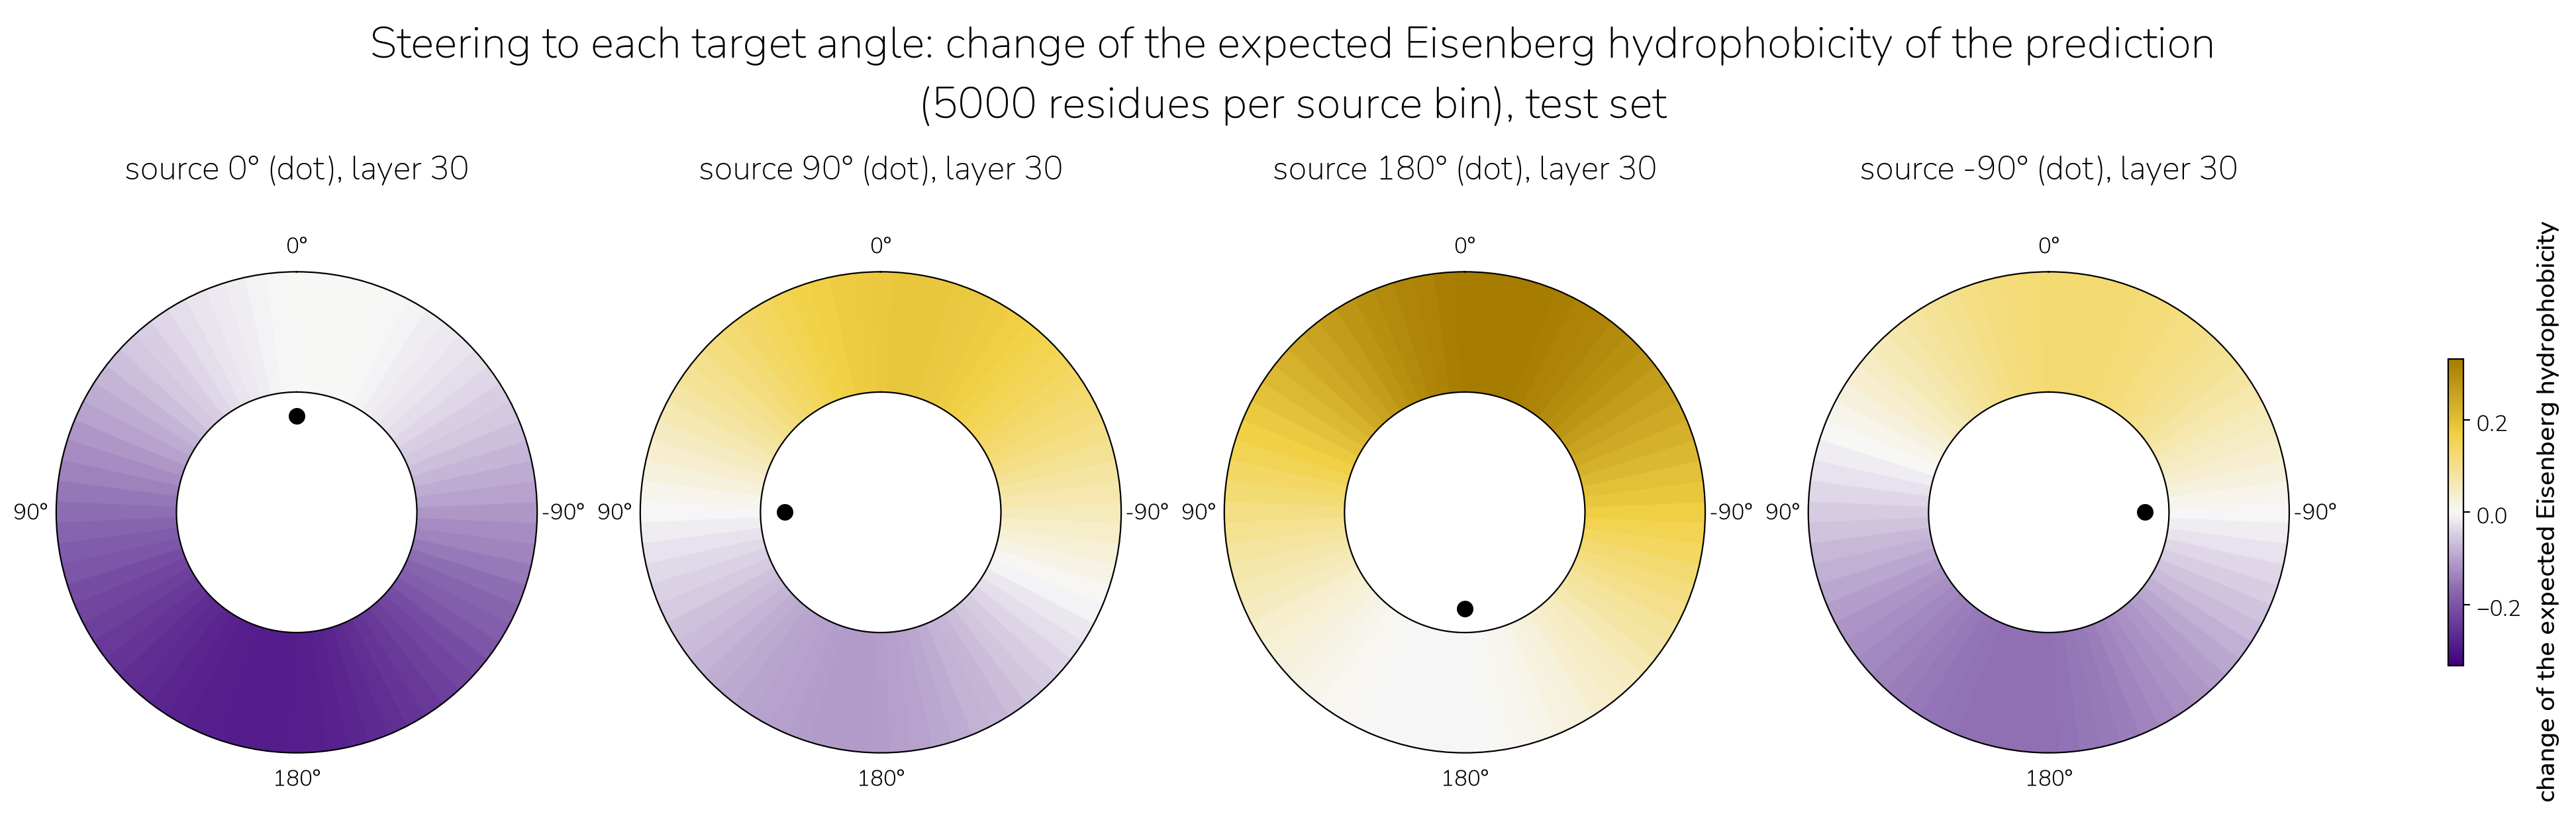

source_angle,layer,control_offset,n,control_delta_mass,control_ci,target_angle,steer_delta_mass,steer_ci
i32,i32,i64,u32,f32,f64,f64,f32,f64
-90,30,-90,5000,-0.000016,0.000421,-180.0,-0.072104,0.001878
-90,30,45,5000,-0.000186,0.000225,-45.0,0.045648,0.00118
-90,30,90,5000,0.000149,0.000324,0.0,0.060056,0.001537
-90,30,180,5000,-0.000145,0.000326,90.0,-0.016962,0.000569
0,30,-90,5000,-0.000149,0.00032,-90.0,-0.055375,0.001447
0,30,45,5000,0.000098,0.000172,45.0,-0.024284,0.000686
0,30,90,5000,-0.000353,0.000398,90.0,-0.07347,0.001912
0,30,180,5000,-0.000605,0.000647,-180.0,-0.135911,0.003194
90,30,-90,5000,-0.00049,0.00042,0.0,0.08022,0.00206


In [4]:
HYDROPHOBIC = "ACGILMFPWYV"  # sign of the Eisenberg consensus scale
EISENBERG = dict(zip("ARNDCQEGHILKMFPSTWYV", [0.62, -2.53, -0.78, -0.90, 0.29, -0.85, -0.74, 0.48, -0.40, 1.38,
                                                1.06, -1.50, 0.64, 1.19, 0.12, -0.18, -0.05, 0.81, 0.26, 1.08]))

# probabilities over the 20 amino acids (renormalised), then the two scores per row
log_probs = results["aa_log_probs"].to_numpy()
p = np.exp(log_probs - log_probs.max(1, keepdims=True))
p /= p.sum(1, keepdims=True)
scores = results.select("accession", "i", "source_angle", "layer", "edit", "kind", "target_angle", "control_offset").with_columns(
    hydrophobic_mass=p[:, [a in HYDROPHOBIC for a in AA]].sum(1),
    expected_hydrophobicity=p @ np.array([EISENBERG[a] for a in AA]),
)
unedited = scores.filter(pl.col("edit") == "none").select("accession", "i", "layer", mass_unedited="hydrophobic_mass", h_unedited="expected_hydrophobicity")
changes = scores.filter(pl.col("edit") != "none").join(unedited, on=["accession", "i", "layer"]).with_columns(
    delta_mass=pl.col("hydrophobic_mass") - pl.col("mass_unedited"),
    delta_h=pl.col("expected_hydrophobicity") - pl.col("h_unedited"),
)
per_edit = changes.group_by("source_angle", "layer", "edit", "kind", "target_angle", "control_offset").agg(
    n=pl.len(), *[pl.col(c).mean().alias(f"mean_{c}") for c in ["delta_mass", "delta_h"]],
    *[(1.96 * pl.col(c).std() / pl.len().sqrt()).alias(f"ci_{c}") for c in ["delta_mass", "delta_h"]],
)
display(unedited.join(residues.select("accession", "i", "source_angle"), on=["accession", "i"]).group_by("source_angle", "layer")
        .agg(pl.col("mass_unedited", "h_unedited").mean()).sort("layer", "source_angle"))


def wheels(column, label, title):
    """One wheel per source bin and layer: ring of 5-degree target sectors, coloured by the mean change; a dot marks the source angle."""
    steer = per_edit.filter(pl.col("kind") == "steer")
    limit = steer[f"mean_{column}"].abs().max()
    norm = Normalize(-limit, limit)
    fig, axes = plt.subplots(len(LAYERS), len(SOURCE_ANGLES), figsize=(4.6 * len(SOURCE_ANGLES) + 1, 6 * len(LAYERS)),
                             subplot_kw={"projection": "polar"}, squeeze=False, layout="constrained")  # room for all titles and labels
    fig.get_layout_engine().set(wspace=0.02, h_pad=0.15)  # wheels close together; some room below the title
    for row, layer in zip(axes, LAYERS):
        for ax, source in zip(row, SOURCE_ANGLES):
            d = steer.filter((pl.col("layer") == layer) & (pl.col("source_angle") == source)).sort("target_angle")
            ax.bar(np.deg2rad(d["target_angle"].to_numpy()), 1, bottom=1, width=np.deg2rad(5), linewidth=0, antialiased=False,
                   color=theme.DELTA(norm(d[f"mean_{column}"].to_numpy())))
            ax.plot(np.deg2rad(source), 0.8, marker="o", markersize=8, color="black")  # inside the ring, at the source angle
            theme.inner_border(ax)
            ax.set_rlim(0, 2)
            ax.set_yticks([])
            ax.grid(False)
            ax.set_theta_zero_location("N")
            ax.set_thetagrids(range(0, 360, 90), ["0°", "90°", "180°", "-90°"])
            ax.set_title(f"source {source}° (dot), layer {layer}", pad=28)  # above the 0° label
    fig.colorbar(ScalarMappable(norm, theme.DELTA), ax=axes, shrink=0.6, label=label)
    fig.suptitle(title, wrap=False)
    plt.show()


wheels("delta_mass", "change of the hydrophobic probability mass",
       f"Steering to each target angle: change of the probability mass on hydrophobic amino acids\n({N_PER_BIN} residues per source bin), test set")
wheels("delta_h", "change of the expected Eisenberg hydrophobicity",
       f"Steering to each target angle: change of the expected Eisenberg hydrophobicity of the prediction\n({N_PER_BIN} residues per source bin), test set")

# steering compared with the random-vector controls of the same norm (target = source + offset)
comparison = (
    per_edit.filter(pl.col("kind") == "random vector").select("source_angle", "layer", "control_offset", "n",
        control_delta_mass="mean_delta_mass", control_ci="ci_delta_mass")
    .with_columns(target_angle=((pl.col("source_angle") + pl.col("control_offset") + 180) % 360 - 180).cast(pl.Float64))
    .join(per_edit.filter(pl.col("kind") == "steer").select("source_angle", "layer", "target_angle", steer_delta_mass="mean_delta_mass",
        steer_ci="ci_delta_mass"), on=["source_angle", "layer", "target_angle"])
    .sort("layer", "source_angle", "control_offset")
)
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
comparison

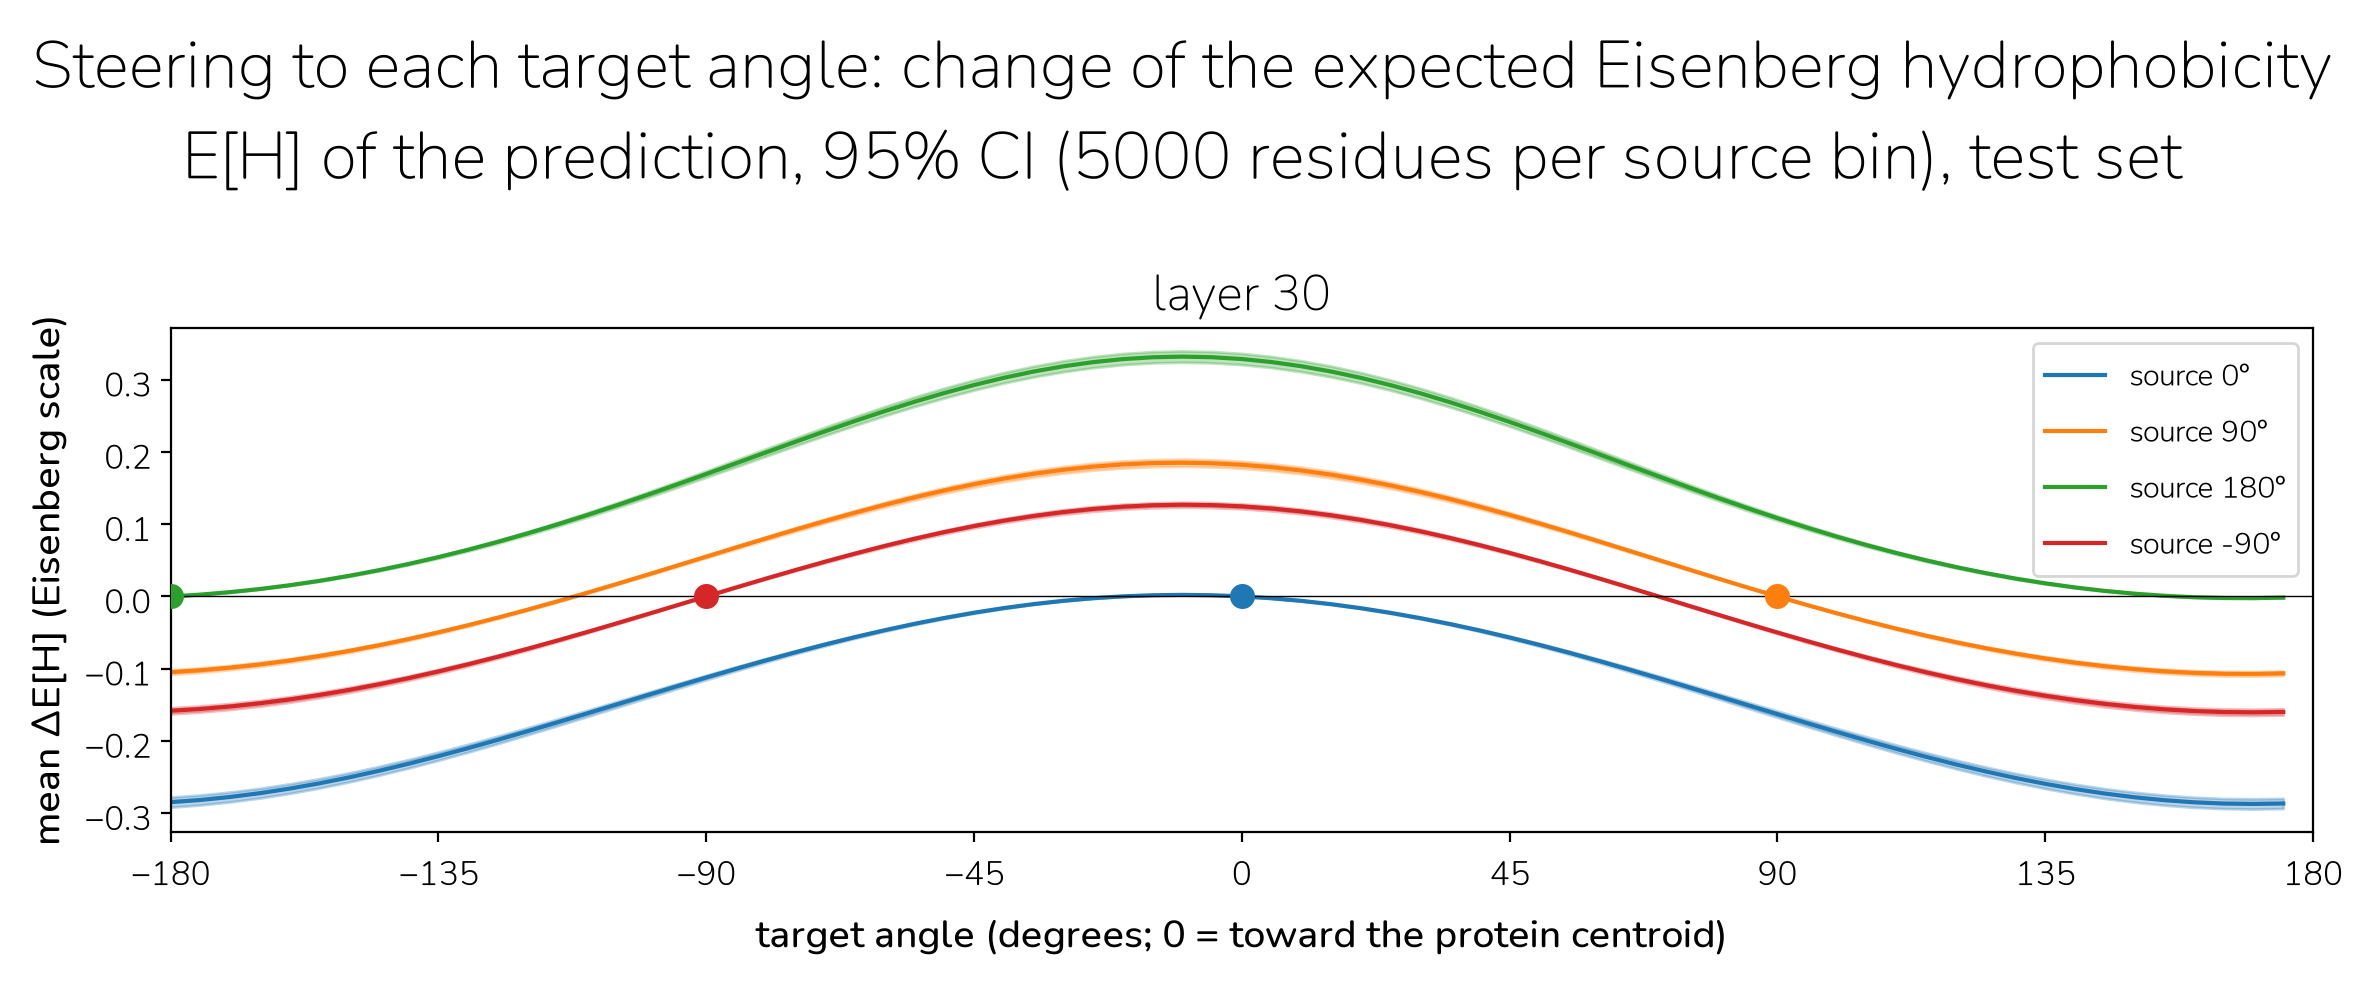

In [5]:
# Change of E[H] against the target angle: one line per source bin with its 95% CI band
fig, axes = plt.subplots(1, len(LAYERS), figsize=(12 * len(LAYERS), 5), squeeze=False)
for ax, layer in zip(axes[0], LAYERS):
    for k, source in enumerate(SOURCE_ANGLES):
        colour = f"C{k}"
        d = per_edit.filter((pl.col("layer") == layer) & (pl.col("source_angle") == source))
        steer = d.filter(pl.col("kind") == "steer").sort("target_angle")
        x, y, ci = steer["target_angle"].to_numpy(), steer["mean_delta_h"].to_numpy(), steer["ci_delta_h"].to_numpy()
        ax.plot(x, y, color=colour, label=f"source {source}°")
        ax.fill_between(x, y - ci, y + ci, color=colour, alpha=0.3)
        at_source = source if source != 180 else -180  # the targets run from -180 to 175 degrees
        ax.plot(at_source, y[x == at_source][0], marker="o", markersize=8, color=colour, zorder=3)  # the source angle, on its curve
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xticks(range(-180, 181, 45))
    ax.set_xlim(-180, 180)
    ax.set_xlabel("target angle (degrees; 0 = toward the protein centroid)")
    ax.set_ylabel("mean ΔE[H] (Eisenberg scale)")
    ax.set_title(f"layer {layer}")
    ax.legend(fontsize="small")
fig.suptitle(f"Steering to each target angle: change of the expected Eisenberg hydrophobicity E[H] of the prediction, 95% CI ({N_PER_BIN} residues per source bin), test set")
plt.tight_layout()
plt.show()

## Canonical examples
One residue of the 0° bin and one of the 180° bin, turned by 180 degrees: the residue whose hydrophobic mass and expected hydrophobicity, before the edit and their changes, are closest to the means of its bin. Probabilities of the 20 amino acids at the masked residue (softmax over the full vocabulary), before and after steering, ranked from highest to lowest, coloured by Eisenberg consensus hydrophobicity; the true amino acid in bold; the last row: all other tokens of the vocabulary together, in grey.

accession,i,source_angle,target,mass_unedited,hydrophobic_mass,delta_mass,h_unedited,expected_hydrophobicity,delta_h
str,i64,i64,i64,f64,f64,f64,f64,f64,f64
"""Q9JLS8""",95,0,-180,0.700157,0.561104,-0.139054,0.286492,-0.002798,-0.28929
"""A9AWD7""",235,180,0,0.443645,0.598995,0.15535,-0.198123,0.13429,0.332414


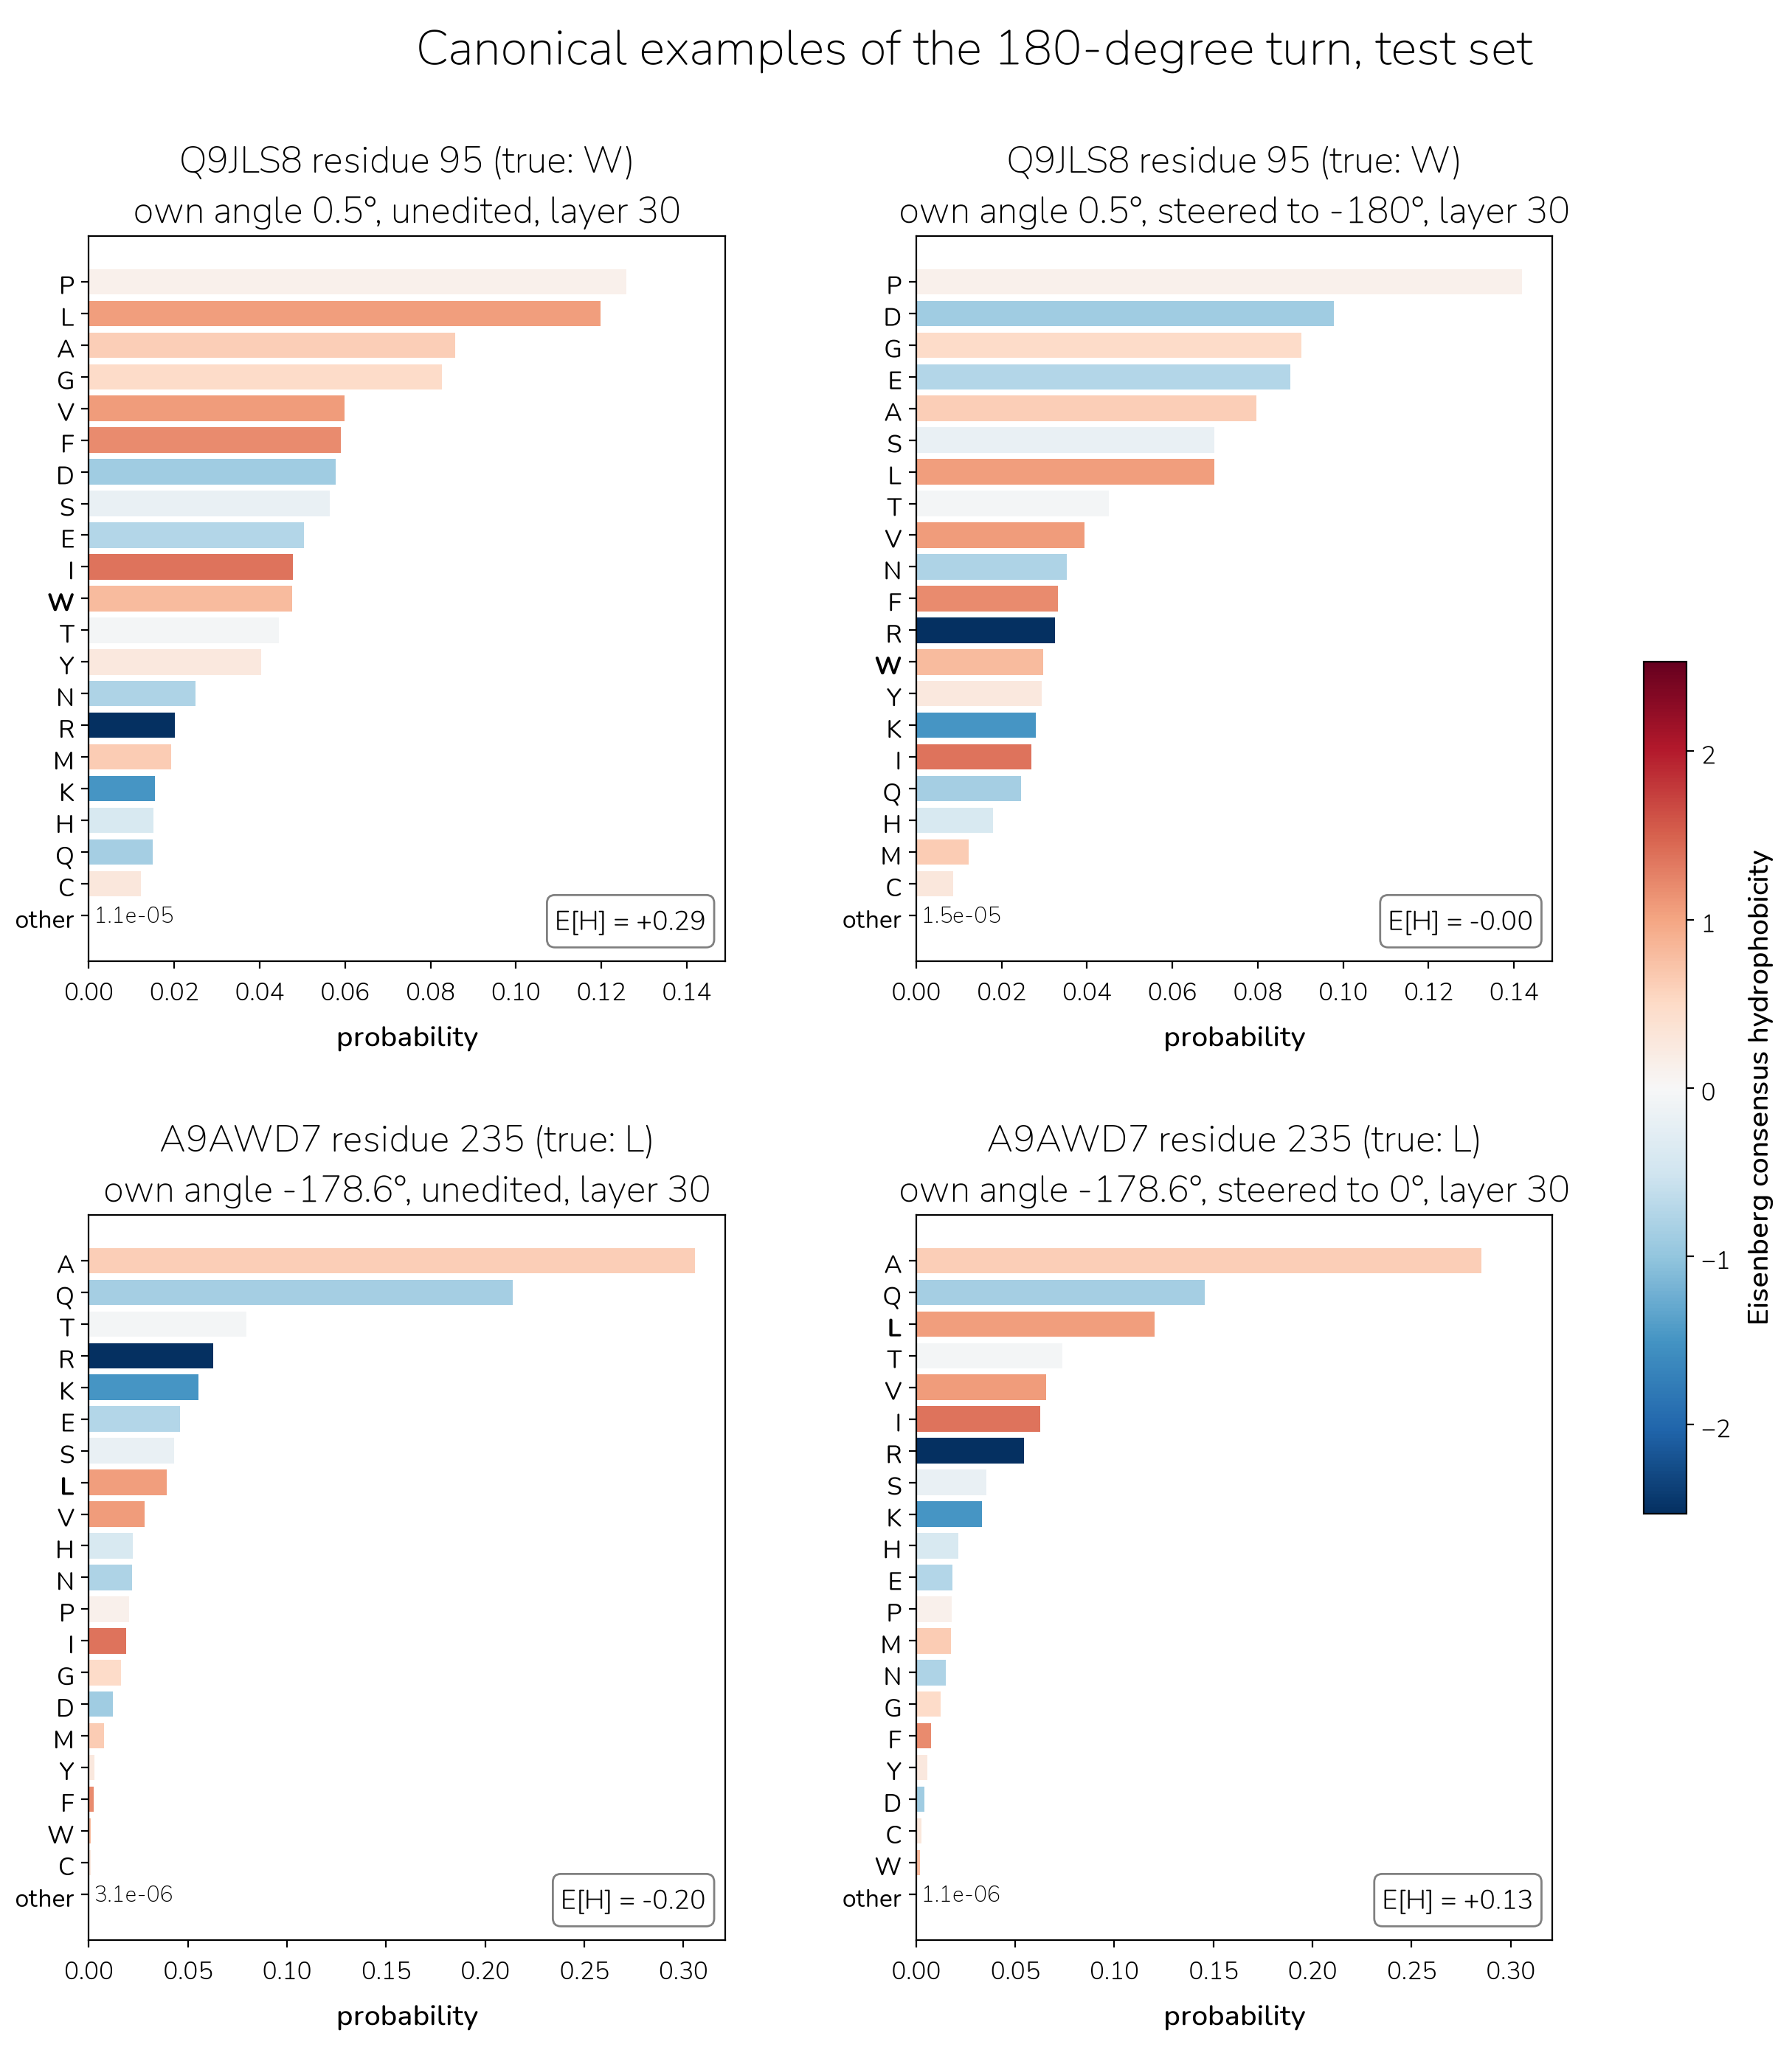

In [6]:
TURN = {0: -180, 180: 0}  # source angle -> target angle of the 180-degree turn
eisenberg = np.array([EISENBERG[a] for a in AA])
colour_norm = Normalize(-np.abs(eisenberg).max(), np.abs(eisenberg).max())  # centred on 0: the sign separates hydrophobic and hydrophilic

# per source bin: the residue closest to the means, distance in standard deviations over both scores before the edit and their changes
examples = []
for source, target in TURN.items():
    turned = changes.filter((pl.col("source_angle") == source) & (pl.col("target_angle") == target))
    distance = sum(((pl.col(c) - pl.col(c).mean()) / pl.col(c).std()) ** 2 for c in ["mass_unedited", "h_unedited", "delta_mass", "delta_h"])
    examples.append(turned.with_columns(distance=distance).sort("distance").row(0, named=True) | {"target": target})
display(pl.DataFrame(examples).select("accession", "i", "source_angle", "target", "mass_unedited", "hydrophobic_mass", "delta_mass",
                                      "h_unedited", "expected_hydrophobicity", "delta_h"))

fig, axes = plt.subplots(len(examples), 2, figsize=(16, 7.5 * len(examples)), sharex="row")
fig.subplots_adjust(wspace=0.3, hspace=0.35)  # room for the titles
for row, example in zip(axes, examples):
    residue = results.filter((pl.col("accession") == example["accession"]) & (pl.col("i") == example["i"]) & (pl.col("layer") == LAYERS[-1]))
    for ax, (name, edit) in zip(row, [("unedited", "none"), (f"steered to {example['target']}°", f"target {example['target']}")]):
        r = residue.filter(pl.col("edit") == edit).row(0, named=True)
        probs = np.exp(np.array(r["aa_log_probs"]))  # the 20 amino acids, in the order of AA (softmax over the full vocabulary)
        order = np.argsort(probs)[::-1]  # highest first
        other = 1 - probs.sum()  # the other tokens of the vocabulary (special tokens, X, B, U, Z, O, ...), together
        ax.barh(np.arange(len(AA)), probs[order], color=theme.HYDROPHOBICITY(colour_norm(eisenberg[order])))
        ax.barh(len(AA), other, color="grey")  # last row
        ax.text(other, len(AA), f" {other:.1e}", va="center", fontsize="small", fontweight=theme.WEIGHTS["note"])
        ax.set_yticks(np.arange(len(AA) + 1), [AA[k] for k in order] + ["other"])
        for label in ax.get_yticklabels():
            label.set_fontweight("bold" if label.get_text() == r["aa"] else "normal")
        ax.invert_yaxis()  # highest at the top
        p_aa = probs / probs.sum()  # renormalised over the 20 amino acids, as in the results above
        ax.text(0.97, 0.03, f"E[H] = {p_aa @ eisenberg:+.2f}", transform=ax.transAxes, ha="right", va="bottom",
                bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "grey"})
        ax.set_xlabel("probability")
        ax.set_title(f"{r['accession']} residue {r['i']} (true: {r['aa']})\nown angle {r['helix_face']:.1f}°, {name}, layer {r['layer']}", wrap=False)
fig.colorbar(ScalarMappable(colour_norm, theme.HYDROPHOBICITY), ax=axes, shrink=0.5, label="Eisenberg consensus hydrophobicity")
fig.suptitle("Canonical examples of the 180-degree turn, test set")
plt.show()